# House Price Prediction

Explore the supplied `Housing.csv`, evaluate a regression model on a held-out split, and make an example prediction. The reusable training and prediction code lives in `house_price.py`.

## 1. Load and inspect the data

The target is `price`. Features include house size and room counts as well as amenities and furnishing status.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from house_price import FEATURES, load_dataset, predict_csv, train_model

DATA_PATH = Path("Housing.csv")
data = load_dataset(DATA_PATH)
print(f"Rows: {len(data):,}")
display(data.head())
display(data.describe(include="all").T)

Rows: 545


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,545.0,NaN,NaN,NaN,4766729.247706,1870439.615657,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,NaN,NaN,NaN,5150.541284,2170.141023,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,NaN,NaN,NaN,2.965138,0.738064,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,NaN,NaN,NaN,1.286239,0.50247,1.0,1.0,1.0,2.0,4.0
stories,545.0,NaN,NaN,NaN,1.805505,0.867492,1.0,1.0,2.0,2.0,4.0
mainroad,545,2,yes,468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guestroom,545,2,no,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
basement,545,2,no,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotwaterheating,545,2,no,520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airconditioning,545,2,no,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Explore prices and features

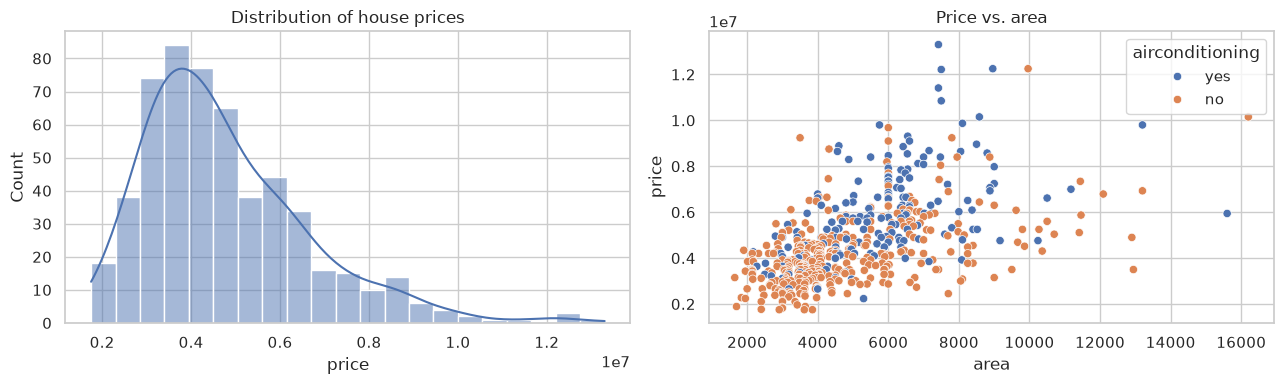

,median,mean,count
furnishingstatus,,,
furnished,5075000.0,5.495696e+06,140
semi-furnished,4585000.0,4.907524e+06,227
unfurnished,3430000.0,4.013831e+06,178


In [2]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=data, x="price", kde=True, ax=axes[0])
axes[0].set_title("Distribution of house prices")
sns.scatterplot(data=data, x="area", y="price", hue="airconditioning", ax=axes[1])
axes[1].set_title("Price vs. area")
plt.tight_layout()
plt.show()

display(data.groupby("furnishingstatus", observed=True)["price"].agg(["median", "mean", "count"]))

## 3. Train and evaluate

The workflow reserves a random 20% holdout for evaluation, reports MAE, RMSE, and R², then saves a final pipeline fitted on all available rows. The saved pipeline includes categorical encoding and numeric preprocessing.

In [3]:
model_path = Path("model/house_price_pipeline.joblib")
metrics = train_model(DATA_PATH, model_path)
print(f"Saved model to {model_path}")
display(pd.Series(metrics, name="holdout score"))

Saved model to model/house_price_pipeline.joblib


mae     1.043179e+06
rmse    1.407390e+06
r2      6.081275e-01
Name: holdout score, dtype: float64

Lower MAE and RMSE indicate smaller prediction errors. R² compares the model with predicting the mean target; values closer to 1 indicate a better fit. These scores are estimates from one holdout split, not a guarantee of performance on future homes.

## 4. Predict a sample home

The input to the model contains the original 12 features only; `price` is not supplied when making a prediction.

In [4]:
sample_home = data.loc[[0], list(FEATURES)].copy()
with TemporaryDirectory() as temporary_directory:
    sample_input = Path(temporary_directory) / "sample.csv"
    sample_output = Path(temporary_directory) / "predictions.csv"
    sample_home.to_csv(sample_input, index=False)
    sample_prediction = predict_csv(model_path, sample_input, sample_output)
display(sample_home)
display(sample_prediction[["predicted_price"]])

,area,bedrooms,bathrooms,stories,parking,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
0,7420,4,2,3,2,yes,no,no,no,yes,yes,furnished


,predicted_price
0,1.054763e+07
